# EEG Feature Analysis

This notebook investigates the discriminative properties of handcrafted EEG features for left-hand (T1) and right-hand (T2) motor imagery.

The analysis focuses on feature distributions, class differences, correlations, and subject-level variability to better understand the limited generalization observed in the baseline models.

## 1. Data Preparation

Load the processed EEG features and retain only motor imagery epochs (T1 and T2). Metadata columns are excluded from the numerical feature set.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_path = Path("../data/processed/eeg_features_all_subjects.csv")
df = pd.read_csv(data_path)

binary_df = df[df["event"].isin(["T1", "T2"])].copy()

metadata_columns = ["event", "subject_id", "recording_id"]
feature_columns = [col for col in binary_df.columns if col not in metadata_columns]

X = binary_df[feature_columns]
y = binary_df["event"]

print("Dataset shape:", binary_df.shape)
print("Feature matrix:", X.shape)
print("Number of subjects:", binary_df["subject_id"].nunique())
print("\nClass distribution:")
print(y.value_counts())

Dataset shape: (225, 24)
Feature matrix: (225, 21)
Number of subjects: 5

Class distribution:
event
T1    113
T2    112
Name: count, dtype: int64


## 2. Feature Distributions by Class

Boxplots are used to compare absolute alpha (8–13 Hz) and beta (13–30 Hz) power between T1 and T2 across C3, Cz, and C4.

The goal is to identify potential class differences, distribution overlap, and variability in EEG power features.

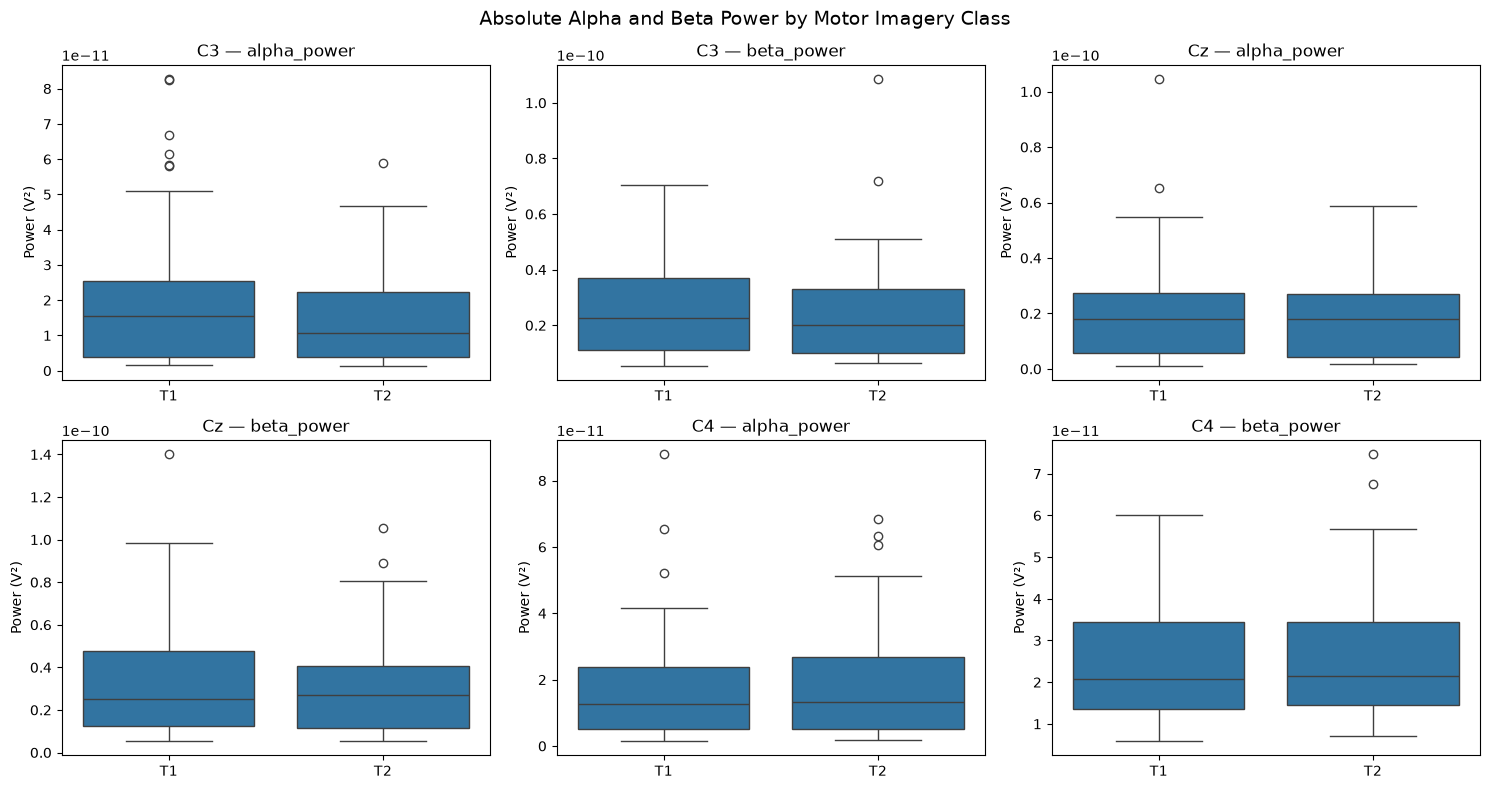

In [2]:
power_features = [col for col in feature_columns 
                  if col.endswith(("_alpha_power", "_beta_power")) and "_relative_" not in col]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, feature in zip(axes.flat, power_features):
    sns.boxplot(data=binary_df, x="event", y=feature, ax=ax, order=["T1", "T2"], showfliers=True)

    ax.set_title(feature.replace(".._", " — "))
    ax.set_xlabel("")
    ax.set_ylabel("Power (V²)")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

plt.suptitle("Absolute Alpha and Beta Power by Motor Imagery Class", fontsize=14)
plt.tight_layout()
plt.show()

### Feature Distribution Analysis

Absolute alpha and beta power distributions show substantial overlap between T1 and T2 across all three channels.

The most noticeable median differences appear in C3 and C4 alpha power, although neither feature provides clear class separation.

Several high-value outliers are present, suggesting considerable variability in EEG power measurements.

## 3. Class Differences and Effect Sizes

Cohen's d is calculated to quantify the magnitude of differences between T1 and T2 for each EEG feature.

This exploratory analysis focuses on effect sizes rather than significance tests, since epochs from the same participants are not independent observations.

In [3]:
from scipy.stats import ttest_ind

effect_results = []

for feature in feature_columns:
    t1 = binary_df.loc[binary_df["event"] == "T1", feature]
    t2 = binary_df.loc[binary_df["event"] == "T2", feature]

    pooled_std = np.sqrt(((len(t1) - 1) * t1.var(ddof=1) +
                          (len(t2) - 1) * t2.var(ddof=1)) / (len(t1) + len(t2) - 2))

    cohens_d = (t1.mean() - t2.mean()) / pooled_std if pooled_std > 0 else np.nan

    effect_results.append({"Feature": feature, 
                           "Cohen's d": cohens_d,
                           "Absolute effect": abs(cohens_d)})

effect_df = pd.DataFrame(effect_results).sort_values(
    "Absolute effect", ascending=False)

display(effect_df.round(3))

,Feature,Cohen's d,Absolute effect
3,C3.._alpha_power,0.242,0.242
11,Cz.._beta_power,0.188,0.188
1,C3.._std,0.174,0.174
2,C3.._rms,0.174,0.174
5,C3.._relative_alpha_power,0.150,0.150
6,C3.._relative_beta_power,-0.150,0.150
14,C4.._mean,0.147,0.147
9,Cz.._rms,0.122,0.122
8,Cz.._std,0.122,0.122
4,C3.._beta_power,0.113,0.113


### Effect Size Analysis

All 21 EEG features showed small class differences (|Cohen's d| ≤ 0.242).

C3 alpha power had the largest effect (d = 0.242), consistent with the boxplot analysis. However, no individual feature demonstrated strong separation between T1 and T2.

The results suggest limited discriminative information in individual handcrafted features. Since epochs are grouped within participants, these pooled effect sizes should be interpreted as descriptive rather than independent statistical evidence.

## 4. Subject-Level Feature Differences

C3 alpha power showed the largest overall class difference. We now compare its mean values for T1 and T2 within each participant to examine whether the direction of this difference is consistent across subjects.

event,T1,T2,T1 - T2
subject_id,,,
S001,3.392e-11,2.115e-11,1.276e-11
S002,2.334e-11,1.693e-11,6.410e-12
S003,2.547e-11,2.890e-11,-3.434e-12
S004,2.975e-12,2.392e-12,5.829e-13
S005,4.567e-12,5.034e-12,-4.670e-13


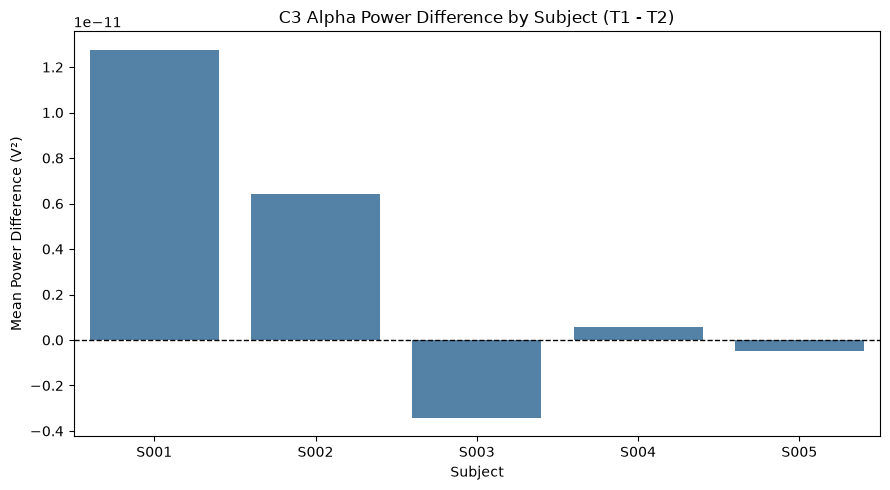

In [4]:
subject_alpha = binary_df.pivot_table(index="subject_id", columns="event", values="C3.._alpha_power", aggfunc="mean")
subject_alpha["T1 - T2"] = subject_alpha["T1"] - subject_alpha["T2"]
display(subject_alpha.map(lambda x: f"{x:.3e}"))

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(x=subject_alpha.index, y=subject_alpha["T1 - T2"], ax=ax, color="steelblue")
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_title("C3 Alpha Power Difference by Subject (T1 - T2)")
ax.set_xlabel("Subject")
ax.set_ylabel("Mean Power Difference (V²)")
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

plt.tight_layout()
plt.show()

### Subject-Level Analysis Results

C3 alpha power showed inconsistent class differences across participants. Mean power was higher for T1 in S001, S002, and S004, but higher for T2 in S003 and S005.

Absolute power levels also varied considerably between subjects, particularly between S001–S003 and S004–S005.

These findings suggest that subject-specific EEG characteristics may contribute to the limited cross-subject generalization observed in the baseline models.

### 5. C3–C4 Alpha Power Asymmetry

We examine the log-ratio of alpha power between C3 and C4 to investigate potential hemispheric differences during left- and right-hand motor imagery.

Unlike absolute power, this measure captures the relative balance between the two sensorimotor channels.

We compare asymmetry between T1 and T2 for each subject.

In [5]:
asymmetry_df = binary_df.copy()
epsilon = 1e-30

asymmetry_df["alpha_asymmetry"] = np.log(asymmetry_df["C3.._alpha_power"].clip(lower=epsilon) /
                                         asymmetry_df["C4.._alpha_power"].clip(lower=epsilon))

subject_asymmetry = asymmetry_df.pivot_table(index="subject_id", columns="event", values="alpha_asymmetry", aggfunc="mean")

subject_asymmetry["T1 - T2"] = (subject_asymmetry["T1"] - subject_asymmetry["T2"])

display(subject_asymmetry.round(3))

event,T1,T2,T1 - T2
subject_id,,,
S001,0.188,-0.244,0.433
S002,0.561,0.130,0.431
S003,-0.207,-0.184,-0.023
S004,-0.157,-0.548,0.391
S005,-0.330,-0.250,-0.080


### Alpha Asymmetry Results

C3–C4 alpha power asymmetry showed a consistent positive T1–T2 difference for S001, S002, and S004 (0.391–0.433).

For S003 and S005, the differences were small and slightly negative.

These findings suggest potentially informative hemispheric patterns, although their consistency across subjects remains limited.

### 6. C3–C4 Beta Power Asymmetry

We calculate the log-ratio of beta power between C3 and C4 to investigate whether hemispheric differences observed in the alpha band are also present in the beta band.

In [6]:
asymmetry_df["beta_asymmetry"] = np.log(asymmetry_df["C3.._beta_power"].clip(lower=epsilon) /
                                        asymmetry_df["C4.._beta_power"].clip(lower=epsilon))

subject_beta_asymmetry = asymmetry_df.pivot_table(index="subject_id", columns="event", values="beta_asymmetry", aggfunc="mean")

subject_beta_asymmetry["T1 - T2"] = (subject_beta_asymmetry["T1"] - subject_beta_asymmetry["T2"])

display(subject_beta_asymmetry.round(3))

event,T1,T2,T1 - T2
subject_id,,,
S001,0.080,-0.070,0.150
S002,0.332,0.090,0.242
S003,-0.031,-0.070,0.040
S004,-0.106,-0.485,0.379
S005,-0.333,-0.193,-0.140


### Beta Asymmetry Results

Beta power asymmetry showed a positive T1–T2 difference for four of five subjects, although the difference for S003 was close to zero.

S005 showed a negative difference in both alpha and beta asymmetry.

Overall, hemispheric asymmetry may capture relevant motor imagery patterns, but the observed differences remain subject-dependent. Their classification value has not yet been established.

## 7. Feature Correlations

A correlation matrix is used to identify strongly related EEG features and potential redundancy in the handcrafted feature set.

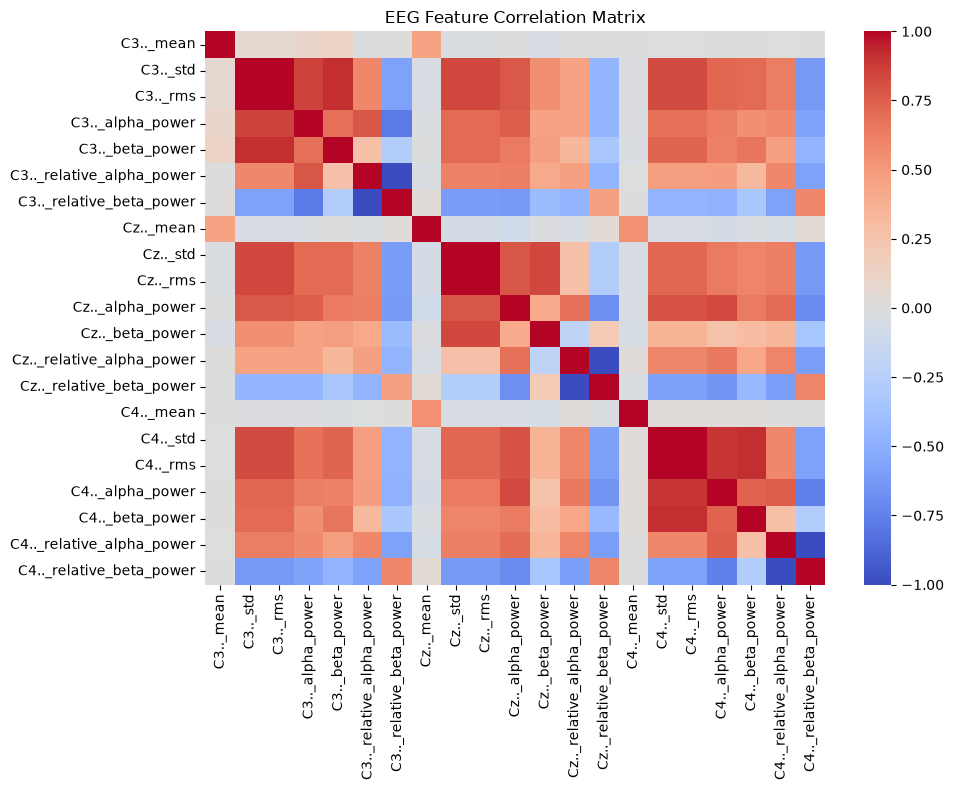

In [7]:
correlation_matrix = X.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1)

plt.title("EEG Feature Correlation Matrix")
plt.tight_layout()
plt.show()

### Correlation Analysis Results

Strong correlations were observed between standard deviation and RMS features, as well as among several absolute power measurements across channels.

Relative alpha and beta power showed perfect negative correlation within each channel due to their complementary definitions.

These results indicate substantial feature redundancy. Reducing redundant features may simplify the model, although any impact on classification performance must be evaluated separately.

## 8. Highly Correlated Features

Feature pairs with an absolute Pearson correlation of at least 0.95 are identified to quantify redundancy in the EEG feature set.

In [8]:
high_corr_pairs = []

for i, feature_1 in enumerate(correlation_matrix.columns):
    for feature_2 in correlation_matrix.columns[i + 1:]:
        corr = correlation_matrix.loc[feature_1, feature_2]

        if abs(corr) >= 0.95:
            high_corr_pairs.append({"Feature 1": feature_1, "Feature 2": feature_2, "Correlation": corr})

high_corr_df = pd.DataFrame(high_corr_pairs)

if not high_corr_df.empty:
    high_corr_df = high_corr_df.sort_values(
        "Correlation", key=abs, ascending=False)

display(high_corr_df.round(3))

,Feature 1,Feature 2,Correlation
1,C3.._relative_alpha_power,C3.._relative_beta_power,-1.0
3,Cz.._relative_alpha_power,Cz.._relative_beta_power,-1.0
5,C4.._relative_alpha_power,C4.._relative_beta_power,-1.0
4,C4.._std,C4.._rms,1.0
2,Cz.._std,Cz.._rms,1.0
0,C3.._std,C3.._rms,1.0


### Highly Correlated Features

Six feature pairs showed near-perfect correlations (|r| ≥ 0.95).

Relative alpha and beta power were perfectly negatively correlated within each channel, while standard deviation and RMS were almost perfectly positively correlated.

These findings confirm substantial redundancy in the feature set and motivate evaluating a reduced feature representation.

## 9. Log-Transformed Band Power

Absolute alpha and beta power features exhibit skewed distributions and high-value outliers.

A logarithmic transformation is applied to examine whether it reduces skewness and improves the visualization of class distributions.

Absolute band-power features transformed:
['C3.._alpha_power', 'C3.._beta_power', 'Cz.._alpha_power', 'Cz.._beta_power', 'C4.._alpha_power', 'C4.._beta_power']


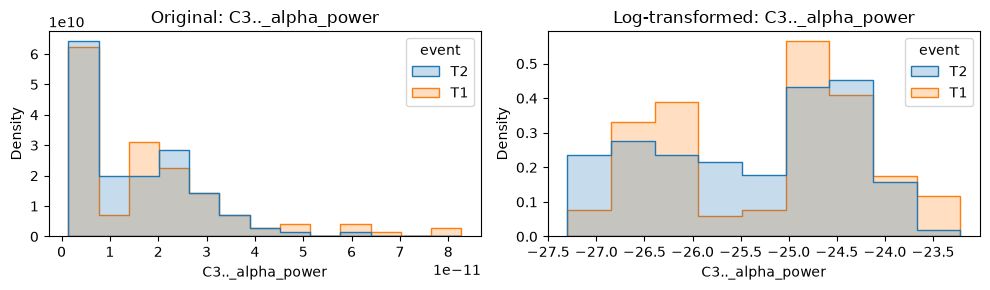

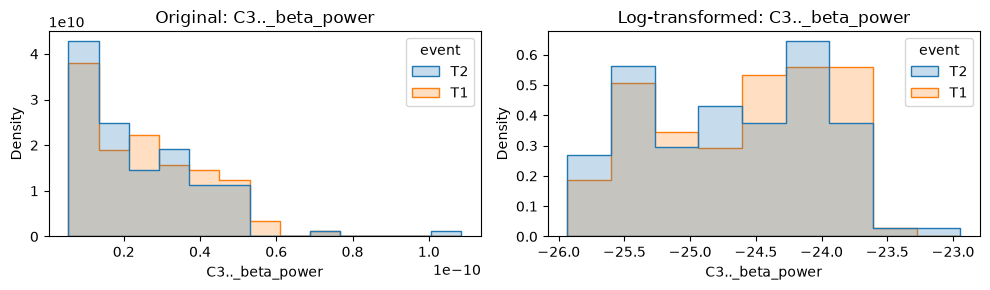

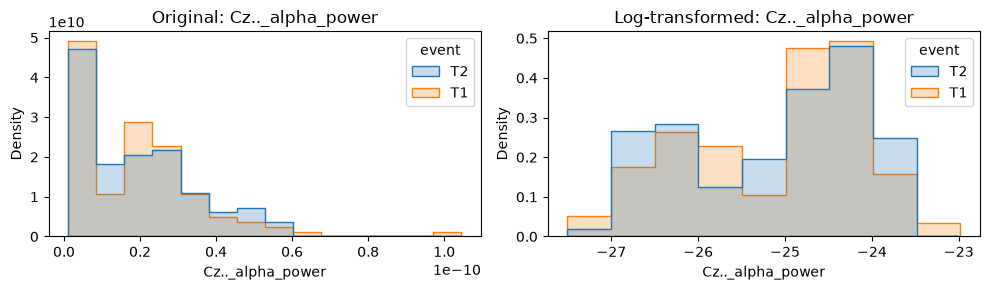

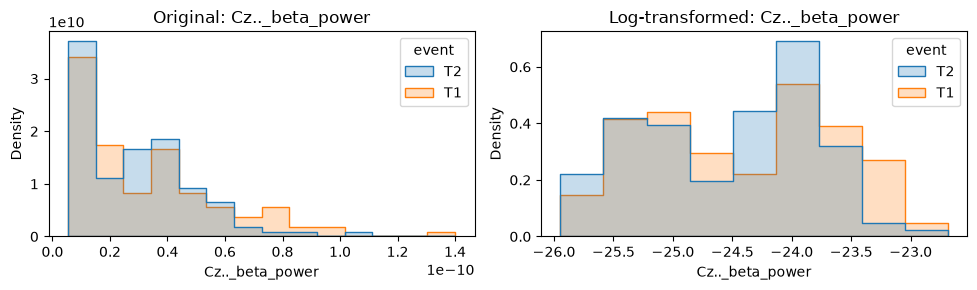

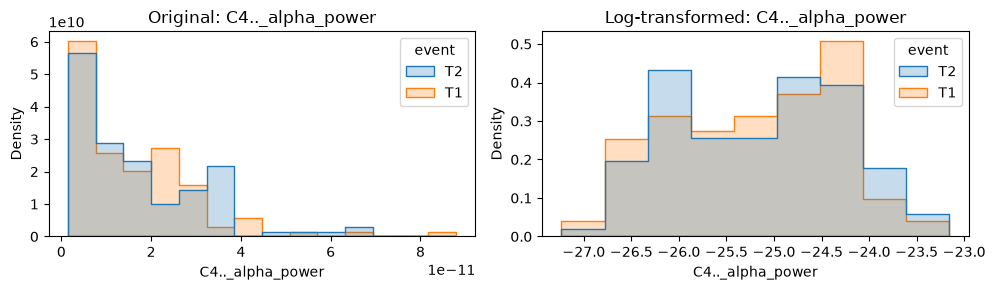

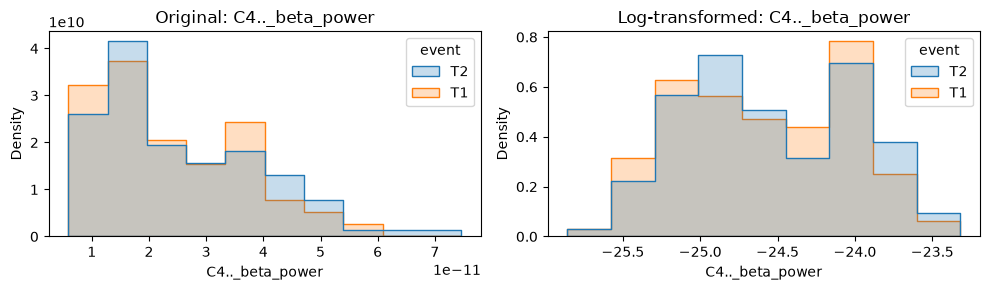

In [9]:
power_columns = [col for col in feature_columns
    if col.endswith(("_alpha_power", "_beta_power")) and "relative" not in col]

X_log = X.copy()
epsilon = 1e-30
X_log[power_columns] = np.log(X_log[power_columns].clip(lower=epsilon))

print("Absolute band-power features transformed:")
print(power_columns)

for feature in power_columns:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(data=binary_df, x=feature, hue="event", element="step", stat="density", common_norm=False, ax=axes[0])
    
    axes[0].set_title(f"Original: {feature}")

    plot_df = binary_df.copy()
    plot_df[feature] = X_log[feature]

    sns.histplot(data=plot_df, x=feature, hue="event", element="step", stat="density", common_norm=False, ax=axes[1])

    axes[1].set_title(f"Log-transformed: {feature}")

    plt.tight_layout()
    plt.show()

### Log-Transformation Results

Log-transformation reduced the right-skewness of absolute alpha and beta power distributions, making their structure easier to visualize.

However, substantial overlap between T1 and T2 remained across all three channels.

Log-transformation may be useful for subsequent modeling, but its effect on classification performance requires separate cross-validation experiments.

## Conclusion

Exploratory analysis of 21 handcrafted EEG features revealed:

- Substantial overlap between T1 and T2 distributions.
- Small individual class differences, with the largest Cohen's d of **0.242** for C3 alpha power.
- Subject-dependent differences in C3 alpha power, including changes in the direction of class differences.
- Six highly correlated feature pairs, indicating redundancy.
- Reduced distribution skewness after log-transformation, but no clear improvement in visual class separation.
- C3–C4 alpha and beta power asymmetry revealed potentially informative hemispheric differences, but their direction and magnitude varied across subjects. Further validation is required before incorporating these measures into the classification pipeline.

These findings suggest that the current handcrafted features provide limited discrimination between motor imagery classes and may contribute to poor cross-subject generalization.

**Next step:** Evaluate spatial EEG features using Common Spatial Patterns (CSP) and compare their classification performance with the handcrafted-feature baselines.